# Fetching the data

The data that is used in the paper is related to various financial instruments:

- GOLD --> Gold futures
- Silver --> Silver futures
- Wheat -->	Wheat futures
- GAZ -->	Natural gas futures
- SP500 -->	S&P 500	
- NSDQ -->	Nasdaq Composite
- VIX -->	Volatility index
- IBEX -->	IBEX 35 (Spain)
- AEX -->	AEX (Netherlands)
- BEL -->	BEL 20 (Belgium)
- DAX -->	DAX (Germany)
- FTSE -->	FTSE 100 (UK)
- SMI -->	Swiss Market Index
- ASX -->	ASX 200 (Australia)
- N225 -->	Nikkei 225
- HIS -->	Hang Seng
- Nifty -->	Nifty 50 (India)
- BVSP -->	Bovespa (Brazil)	
- NZX -->	NZX 50 (New Zealand)
- US yield  -->	US 10-year Treasury

In [1]:
%pip install pandas requests yfinance
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
from pathlib import Path
 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import yfinance as yf

In [3]:
START = "2016-02-01"
END = "2026-02-28" 
PERIOD = '1d'

OUT = Path("data/raw")
OUT.mkdir(parents=True, exist_ok=True)

YAHOO = {
    "gold":   ["GC=F"],
    "silver": ["SI=F"],
    "wheat":  ["ZW=F"],
    "gaz":    ["NG=F"],
    "sp500":  ["^GSPC"],
    "nsdq":   ["^IXIC"],
    "vix":    ["^VIX"],
    "ibex":   ["^IBEX"],
    "aex":    ["^AEX"],
    "bel":    ["^BFX"],
    "dax":    ["^GDAXI"],
    "ftse":   ["^FTSE"],
    "smi":    ["^SSMI"],
    "asx":    ["^AXJO"],
    "n225":   ["^N225"],
    "his":    ["^HSI"],
    "nifty":  ["^NSEI"],
    "bvsp":   ["^BVSP"],
    "nzx":    ["^NZ50"],
    "usyield": ["^TNX"],
    "ta35":   ["TA35.TA"],
    "oil": ["CL=F"]
}

In [4]:
def fetch_single_asset(name):
    ticker = YAHOO[name]

    try:
        data = yf.download(
            tickers=ticker,
            interval=PERIOD,
            start=START,
            end=END
        )

        close = data["Close"].iloc[:, 0]
        
        close.name = name
        return close

    except Exception as e:
        print(f"{name}: {e}")
        return None

def fetch_all():

    # Fetch Yahoo data
    dico = {}

    for name in YAHOO.keys():
        result = fetch_single_asset(name)

        if result is not None:
            dico[name] = result

    yahoo_df = pd.concat(dico, axis=1, sort=True)

    # Fetch US yield data
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10"
    r = requests.get(url, timeout=30)
    r.raise_for_status()

    df = pd.read_csv(
        io.StringIO(r.text),
        index_col=0,
        parse_dates=True
    )

    usyield = pd.to_numeric(df.iloc[:, 0], errors="coerce").loc[START:END]
    usyield.name = "us_yield"

    # Combine all data
    data = pd.concat(
        [yahoo_df, usyield],
        axis=1,
        sort=True
    )

    return data

def check_data_validity(data: pd.DataFrame) -> pd.DataFrame:

    # Check the validity of the timestamps
    if not isinstance(data.index, pd.DatetimeIndex):
        print("The index of the data is not a DatetimeIndex.")
        data.index = pd.to_datetime(data.index, errors="raise")
        print("Solved the problem. The indexes are now datetimes.\n")

    # Check the ordering of observations
    if not data.index.is_monotonic_increasing:
        print("The observations are not properly ordered.")
        data.sort_index(ascending=True, inplace=True)
        print("The observations are now properly ordered.\n")

    # Check for duplicate timestamps
    if not data.index.is_unique:
        print("The index contains duplicate timestamps.")
        data = data.loc[~data.index.duplicated(keep="last")]
        print("Duplicate timestamps removed; last observation kept.\n")

    # Check for missing values
    missing_cols = data.columns[data.isna().any()]

    if len(missing_cols) > 0:
        print("Missing values detected.")
        data.loc[:, missing_cols] = data.loc[:, missing_cols].ffill()

        remaining_missing = data.columns[data.isna().any()]

        if len(remaining_missing) > 0:
            print("Some missing values remain after forward filling. Applying backward filling for leading missing values.")
            data.loc[:, remaining_missing] = (data.loc[:, remaining_missing].bfill())

        print("Missing-value handling completed.\n")

    print("Data validity check completed successfully.")
    
    return data

def build_features(data: pd.DataFrame, lag_order: int = 10, target_col: str = "oil") -> tuple[pd.DataFrame]:

    # Remove observations with nonpositive prices.
    # Also remove the next observation if its price is nonpositive

    # col_target = data[target_col]
    # valid_col = col_target.gt(0) & col_target.shift(-1).gt(0)
    # data = data.loc[valid_col].copy()

    data = data.copy()

    return_cols = data.columns.tolist()
    predictions_cols = []

    # transform the VIX in a dummy variable
    data["vix_dummy"] = (data["vix"] > 20).astype("int8")
    predictions_cols.append("vix_dummy")

    # transform every columns into returns except the vix column
    # I did a forward:backward fill so when computing returns, there will be articial zeros in the dataset. We should think about it
    data[return_cols] = data[return_cols].pct_change(fill_method=None)

    # compute lag up to order 10 of all the columns
    lag_features = {
        f"{col}_lag_{i}": data[col].shift(i)
        for col in return_cols
        for i in range(1, lag_order+1)
    }
    predictions_cols.extend(lag_features.keys())
    data = pd.concat([data, pd.DataFrame(lag_features, index=data.index)], axis=1)

    # moving_averages on the target_col up order 10. we exclude order 1 since it is equivalent to just seeing lag 1. It would introduce a duplicate column
    ma_features = {
        f"{target_col}_ma{i}": data[target_col].rolling(window=i, min_periods=2).mean()
        for i in range(2, lag_order + 1)
    }
    predictions_cols.extend(ma_features.keys())
    data = pd.concat([data, pd.DataFrame(ma_features, index=data.index)],axis=1)

    prediction_dataset = data[predictions_cols+[target_col]].dropna()
    target = prediction_dataset[target_col]
    features =  prediction_dataset[predictions_cols]
    
    return features, target, data[return_cols]

def visualize_returns(returns_data: pd.DataFrame) -> None:
    for col in returns_data.columns:
        fig, ax = plt.subplots(figsize=(12, 4))

        ax.plot(returns_data.index, returns_data[col], linewidth=0.8)
        ax.set_title(f"Returns of {col}")
        ax.set_xlabel("Date")
        ax.set_ylabel("Return")
        ax.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()
        

In [5]:
allData = fetch_all()
cleaned_data = check_data_validity(allData)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%********

Missing values detected.
Missing-value handling completed.

Data validity check completed successfully.


# Testing the models

## Model 1: Regression Tree

In [6]:
from dataclasses import dataclass
import math

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, clone
from sklearn.model_selection import TimeSeriesSplit
from joblib import Parallel, delayed


@dataclass
class Backtester:
    """Walk-forward backtester for time-series prediction."""

    estimator: BaseEstimator = None
    max_train_size: int = 36
    test_size: int = 1
    start_date: str = START
    end_date: str | None = None
    name: str | None = None

    def __post_init__(self):
        if self.estimator is None:
            from sklearn.tree import DecisionTreeRegressor
            self.estimator = DecisionTreeRegressor(
                max_depth=5,
                min_samples_leaf=10,
                random_state=42,
            )

    def compute_predictions(
        self,
        X: pd.DataFrame,
        y: pd.Series | pd.DataFrame,
        n_jobs: int = 1,
    ):
        """Generate out-of-sample predictions using walk-forward splits."""

        # Align features and target by timestamp.
        common_idx = X.index.intersection(y.index).sort_values()
        X = X.loc[common_idx].sort_index().loc[:self.end_date]
        y = y.loc[X.index]

        # Predict only from start_date onward, retaining earlier data for training.
        n_test = len(X.loc[self.start_date:])
        if n_test == 0:
            raise ValueError("No observations found on or after start_date.")

        n_splits = math.ceil(n_test / self.test_size)
        if n_splits >= len(X):
            raise ValueError("Not enough observations for walk-forward training.")

        cv = TimeSeriesSplit(
            max_train_size=self.max_train_size,
            test_size=self.test_size,
            n_splits=n_splits,
        )

        def fit_predict(train, test):
            model = clone(self.estimator)
            model.fit(X.iloc[train], y.iloc[train])
            return model.predict(X.iloc[test]), model, test

        results = Parallel(n_jobs=n_jobs)(
            delayed(fit_predict)(train, test)
            for train, test in cv.split(X)
        )

        # Combine predictions and retain only the requested evaluation period.
        predictions = np.concatenate([result[0] for result in results])
        test_indices = np.concatenate([result[2] for result in results])
        pred_idx = X.index[test_indices]

        mask = pred_idx >= pd.Timestamp(self.start_date)
        if self.end_date is not None:
            mask &= pred_idx <= pd.Timestamp(self.end_date)

        predictions = predictions[mask]
        pred_idx = pred_idx[mask]

        if isinstance(y, pd.DataFrame):
            self.predictions_ = pd.DataFrame(
                predictions, index=pred_idx, columns=y.columns
            )
        else:
            self.predictions_ = pd.Series(
                np.asarray(predictions).reshape(-1),
                index=pred_idx,
                name=self.name or "prediction",
            )

        self.actual_ = y.loc[pred_idx]
        self.estimators_ = tuple(result[1] for result in results)
        self.cv_ = cv

        return self

    def train(
        self,
        X: pd.DataFrame,
        y: pd.Series | pd.DataFrame,
    ):
        """Run the walk-forward prediction procedure."""

        self.compute_predictions(X, y)
        return self.predictions_


def plot_result(predictions, actual):
    plt.figure(figsize=(8, 8))

    plt.scatter(predictions, actual, alpha=0.6)

    # Perfect prediction reference line
    limits = [
        min(np.min(predictions), np.min(actual)),
        max(np.max(predictions), np.max(actual))
    ]
    plt.plot(limits, limits, "r--", label="Perfect predictions")

    plt.xlabel("Predicted oil returns")
    plt.ylabel("Real oil returns")
    plt.title("Real vs Predicted Oil Returns")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.axis("equal")
    plt.tight_layout()
    plt.show()


In [8]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

features, target, returns_data = build_features(cleaned_data,lag_order=10,target_col="oil")

X =  features
y = target

# Align X and y and ensure chronological order.
data = X.join(y.rename("__target__"), how="inner").sort_index()
data = data.replace([np.inf, -np.inf], np.nan).dropna()

X_clean = data.drop(columns="__target__")
y_clean = data["__target__"]

# Keep the period from 2022 onward for final evaluation only.
tuning_end = "2021-12-31"
X_tune = X_clean.loc[:tuning_end]
y_tune = y_clean.loc[X_tune.index]

cv = TimeSeriesSplit(
    n_splits=5,
    max_train_size=120,
    test_size=30,
)

models_and_params = {
    "Decision Tree": (
        DecisionTreeRegressor(random_state=42),
        {
            "max_depth": [2, 3, 5, 8],
            "min_samples_leaf": [5, 10, 20, 30],
            "max_features": [1.0, 0.5, "sqrt"],
        },
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=42, n_jobs=1),
        {
            "n_estimators": [100, 200, 400],
            "max_depth": [3, 5, 8],
            "min_samples_leaf": [5, 10, 20, 30],
            "max_features": [1.0, 0.5, "sqrt"],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=42),
        {
            "n_estimators": [50, 100, 200, 300],
            "learning_rate": [0.01, 0.03, 0.05, 0.1],
            "max_depth": [1, 2, 3],
            "min_samples_leaf": [5, 10, 20, 30],
            "subsample": [0.7, 0.9, 1.0],
        },
    ),
}

best_models = {}
tuning_results = {}

for name, (model, param_grid) in models_and_params.items():
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=25,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True,
        error_score="raise",
    )

    search.fit(X_tune, y_tune)

    best_models[name] = search.best_estimator_
    tuning_results[name] = {
        "best_params": search.best_params_,
        "cv_rmse": -search.best_score_,
    }

    print(f"\n{name}")
    print("Best parameters:", search.best_params_)
    print("Validation RMSE:", -search.best_score_)



Decision Tree
Best parameters: {'min_samples_leaf': 20, 'max_features': 1.0, 'max_depth': 5}
Validation RMSE: 0.01626835301550244

Random Forest
Best parameters: {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 1.0, 'max_depth': 5}
Validation RMSE: 0.014684502438592723

Gradient Boosting
Best parameters: {'subsample': 0.9, 'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 2, 'learning_rate': 0.05}
Validation RMSE: 0.012157361365022054


In [9]:
results = {}
backtesters = {}

for name, best_model in best_models.items():
    backtester = Backtester(
        estimator=best_model,
        max_train_size=50,
        test_size=20,
        start_date="2022-01-01",
        name=name,
    )

    predictions = backtester.train(X_clean, y_clean)

    results[name] = (predictions, backtester.actual_)
    backtesters[name] = backtester


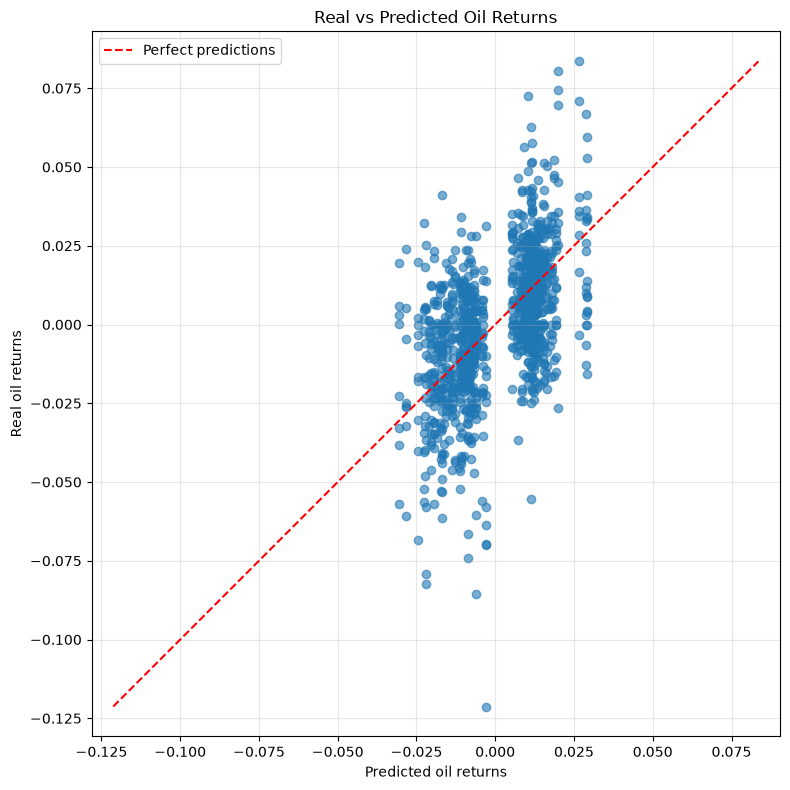

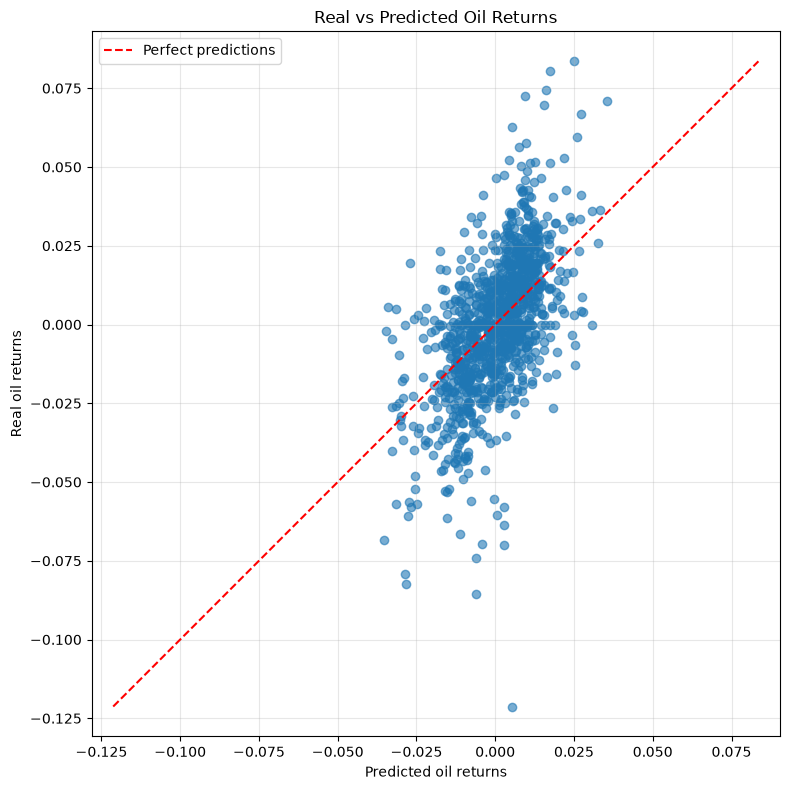

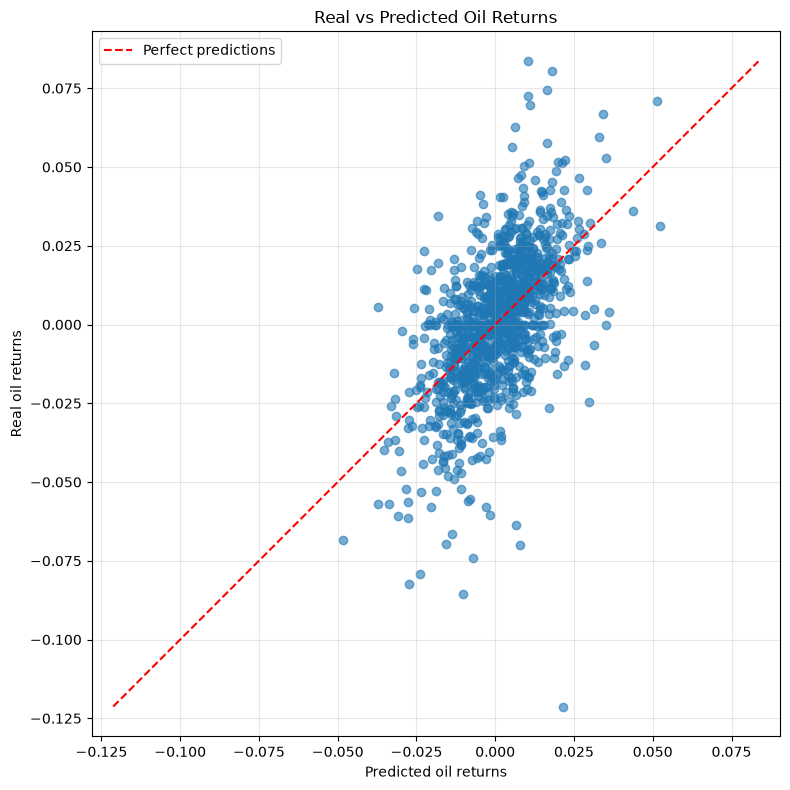

In [10]:
for name, (predictions, actual) in results.items():
    plot_result(predictions,actual)

In [11]:
import numpy as np
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,)

# Vérifier que les prédictions et les valeurs réelles sont alignées.
for name, (predictions, actual) in results.items():
    print(name)
    actual = np.asarray(actual).ravel()
    predicted = np.asarray(predictions).ravel()

    rmse_model = np.sqrt(mean_squared_error(actual, predicted))
    rmse_zero = np.sqrt(mean_squared_error(actual, np.zeros_like(actual)))

    mae_model = mean_absolute_error(actual, predicted)
    mae_zero = mean_absolute_error(actual, np.zeros_like(actual))

    print(f"Model RMSE:      {rmse_model:.6f}")
    print(f"Zero baseline RMSE: {rmse_zero:.6f}")
    print(f"Model MAE:       {mae_model:.6f}")
    print(f"Zero baseline MAE:  {mae_zero:.6f}")
    print(f"R²:              {r2_score(actual, predicted):.4f}")
    print()

Decision Tree
Model RMSE:      0.019072
Zero baseline RMSE: 0.022365
Model MAE:       0.014487
Zero baseline MAE:  0.016787
R²:              0.2728

Random Forest
Model RMSE:      0.018310
Zero baseline RMSE: 0.022365
Model MAE:       0.013785
Zero baseline MAE:  0.016787
R²:              0.3297

Gradient Boosting
Model RMSE:      0.018274
Zero baseline RMSE: 0.022365
Model MAE:       0.013443
Zero baseline MAE:  0.016787
R²:              0.3324

